# Wichtigste stetige Verteilungen

Nachdem wir ausführlich über die Gaussverteilung gesprochen haben, wollen wir einen Überblick über einige der wichtigsten stetigen Verteilungen bekommen, ähnlich wie wir ihn bereits für diskrete Verteilungen gewonnen haben. Dazu benutzen wir das Python-Modul `scipy.stats`.

## SciPy Statistics

In [1]:
import numpy as np
np.random.seed(12321)

import scipy.stats as st

# Zufallsvariable mit N(3,2^2)-Verteilung erzeugen:
X = st.norm(loc=3, scale=2)
# samples ziehen:
Xsamples = X.rvs(size=4)
print("some examples:",Xsamples)

some examples: [4.02801895 1.9033209  6.49477125 1.83362523]


In [2]:
# Verteilung checken:
Xsamples = X.rvs(size=1000)
print("mean:", np.mean(Xsamples), "expected", X.mean()) # 3
print("std:", np.std(Xsamples), "expected", X.std()) # 2
print("3rd moment:", X.moment(3))
print("4th moment:", X.moment(4))
print("entropy:", X.entropy())

mean: 3.0004822746684243 expected 3.0
std: 1.9994507762900595 expected 2.0
3rd moment: 62.99999999999999
4th moment: 344.99999999999994
entropy: 2.112085713764618


In [3]:
# Daten fitten:
mu, sigma = st.norm.fit(Xsamples)
print(mu, sigma)

3.0004822746684243 1.9994507762900595


Es gibt noch weitere praktische Methoden, etwa `st.norm.sf`, die 'survival function', definiert als 1-cdf oder `st.norm.logpdf`, falls man direkt den Logarithmus der Dichtefunktion verwenden möchte (beide Methoden sind potentiell schneller, als das von Hand / zu Fuß auszurechnen).

## Matplotlib

Wir werden uns von den Verteilungen jeweils Plots der Dichtefunktionen (pdf) und der kumulierten Verteilungsfunktionen (cdf) anschauen. Dazu verwenden wir das Python-Modul `matplotlib.pyplot`. Es emuliert das Verhalten von MATLAB. Wir werden uns noch ausführlicher mit Matplotlib beschäftigen.

In [4]:
from matplotlib import pyplot as plt

sample[:10] = [5.96301841 5.60942173 5.72908826 5.80068973 5.59819708 5.35377228
 6.093922   6.36189002 5.42430139 5.87334923]


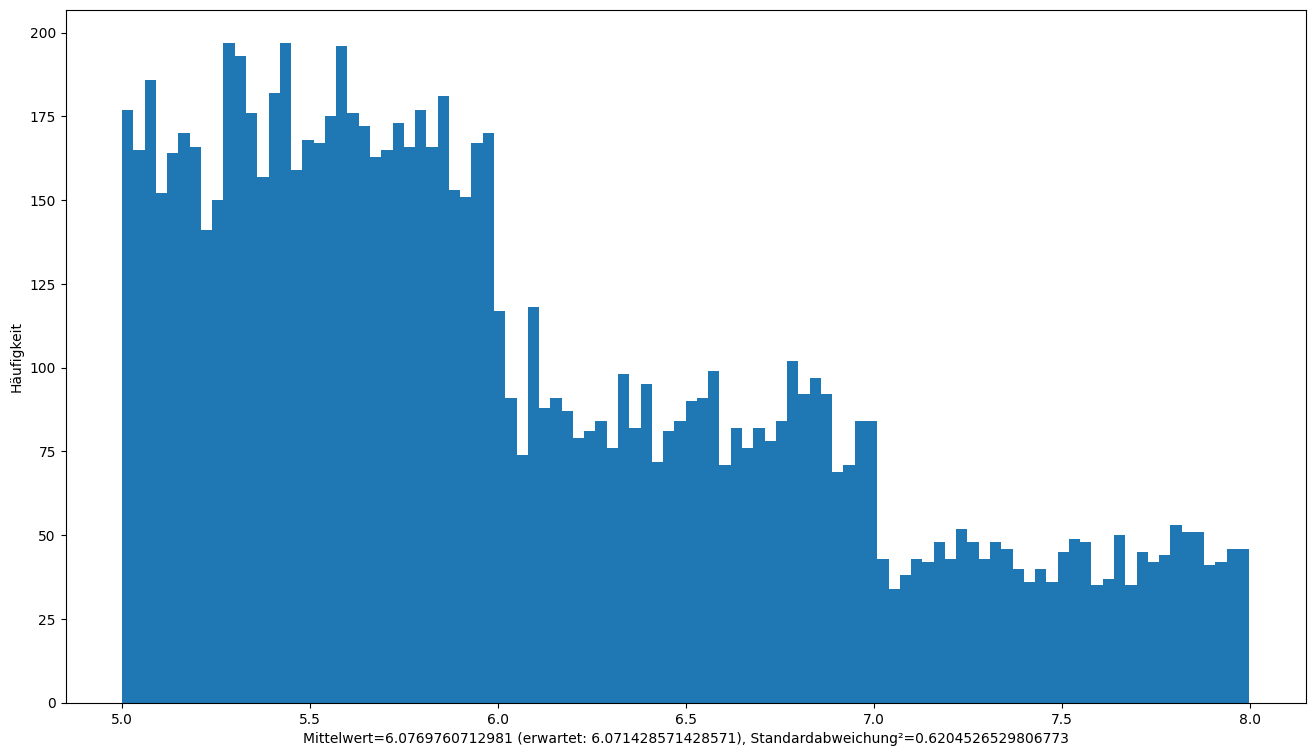

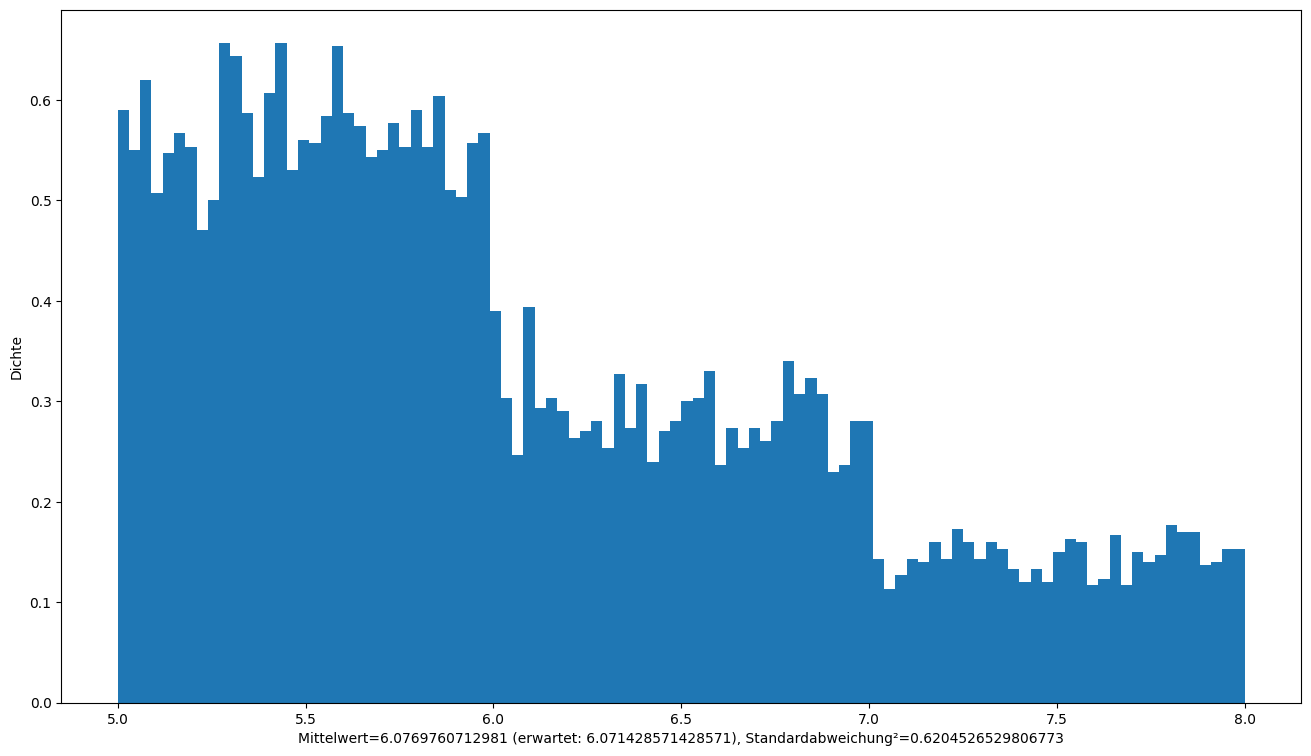

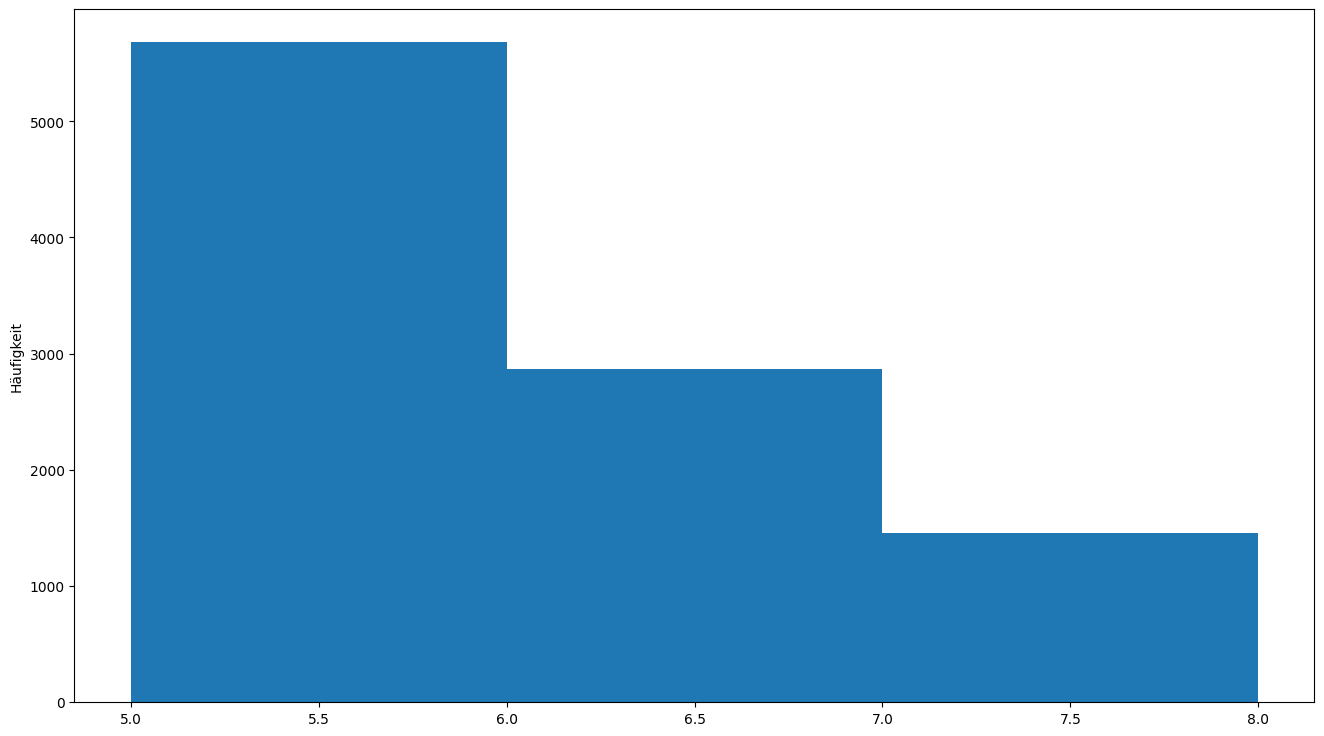

In [5]:
# Größe der Plotausgabe anpassen:
plt.rcParams["figure.figsize"] = (16,9)

# Sample der Verteilung von einer früheren Übungsaufgabe:
sample = np.random.choice(3, 10000, p=[4/7,2/7,1/7]) + 5 + np.random.random(10000)
print("sample[:10] =", sample[:10])
# Histogramm plotten:
plt.hist(sample, bins=100)
plt.ylabel("Häufigkeit")
plt.xlabel("Mittelwert="+str(np.mean(sample))+" (erwartet: "+str(6+1/14)+"), Standardabweichung²="+str(np.std(sample)**2))
plt.show()

plt.hist(sample, bins=100, density=True)
plt.ylabel("Dichte")
plt.xlabel("Mittelwert="+str(np.mean(sample))+" (erwartet: "+str(6+1/14)+"), Standardabweichung²="+str(np.std(sample)**2))
plt.show()

# Histogramm mit wenig bins:
plt.hist(sample, bins=3)
plt.ylabel("Häufigkeit")
plt.show()

Zum Plotten einer Funktion definieren wir diese als Python-Methode und rechnen hinreichend viele Werte aus, zwischen denen dann interpoliert wird:

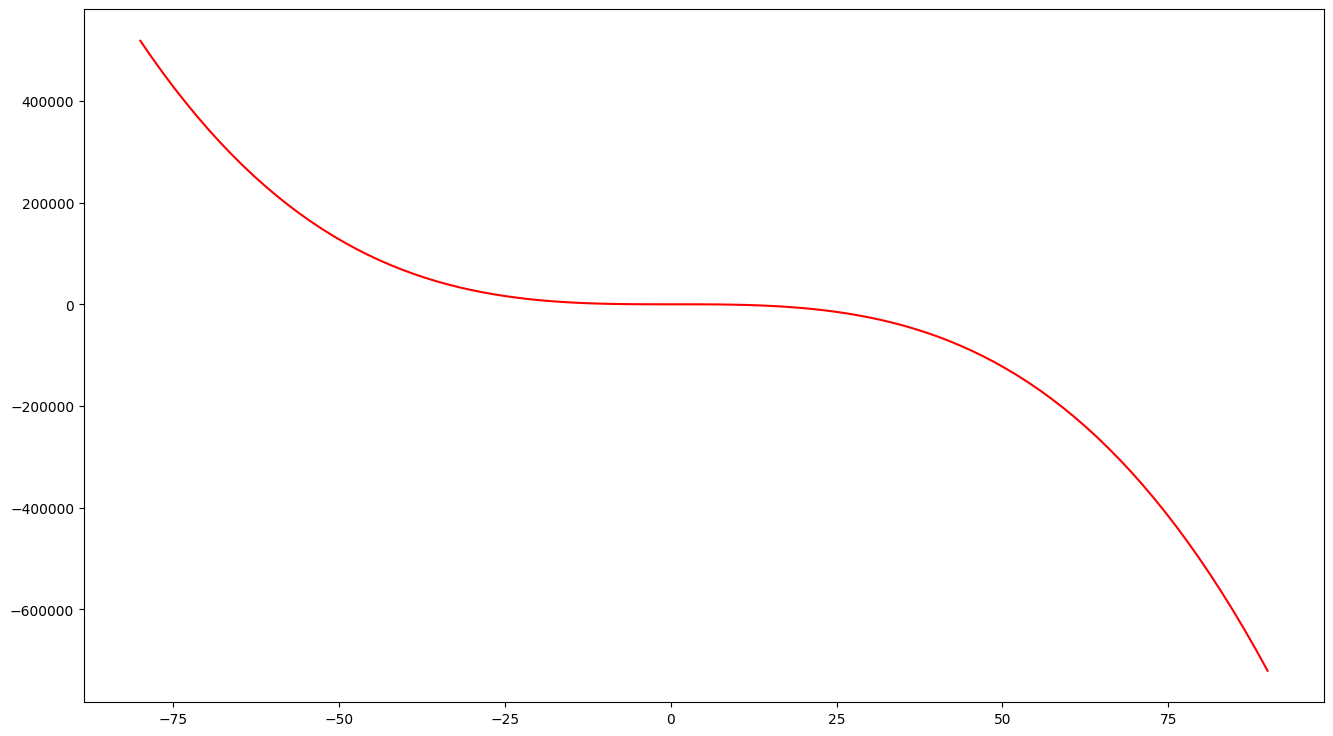

In [6]:
# Funktion x |-> 3+2x+x²-x³ auf Intervall [-80,90] plotten:
def f(x):
    return 3 + 2*x + x**2 - x**3

x = np.linspace(-80, 90, 100)
plt.plot(x, f(x), color='red')
plt.show()

Damit kümmern wir uns nun um die wichtigsten stetigen Verteilungen:

## Normalverteilung

* Parameter $\mu,\sigma$, Notation $\mathcal{N}(\mu,\sigma^2)$
* Dichte $\phi(x) = \frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2\sigma^2}}$
* Erwartungswert $\mu$
* Varianz $\sigma^2$
* Höhere ungerade zentrale Momente sind alle $0$ \
  (daher sind ungerade Momente ein Maß für nicht-Normalität)
* Maximale Entropie bei festem Erwartungswert und fester Varianz und Träger ganz $\mathbb{R}$
* ZGWS: Folge iid Zufallsvariablen $X_i$, dann $\sum_{i=1}^N X_i \xrightarrow{N \to \infty} \mathcal{N}(\mu,\sigma^2)$
* Anwendungsbeispiele:
  * Messfehler in physikalischen Systemen
  * Fertigungsgenauigkeit
  * Biologische Größen (Körperlänge etc.)

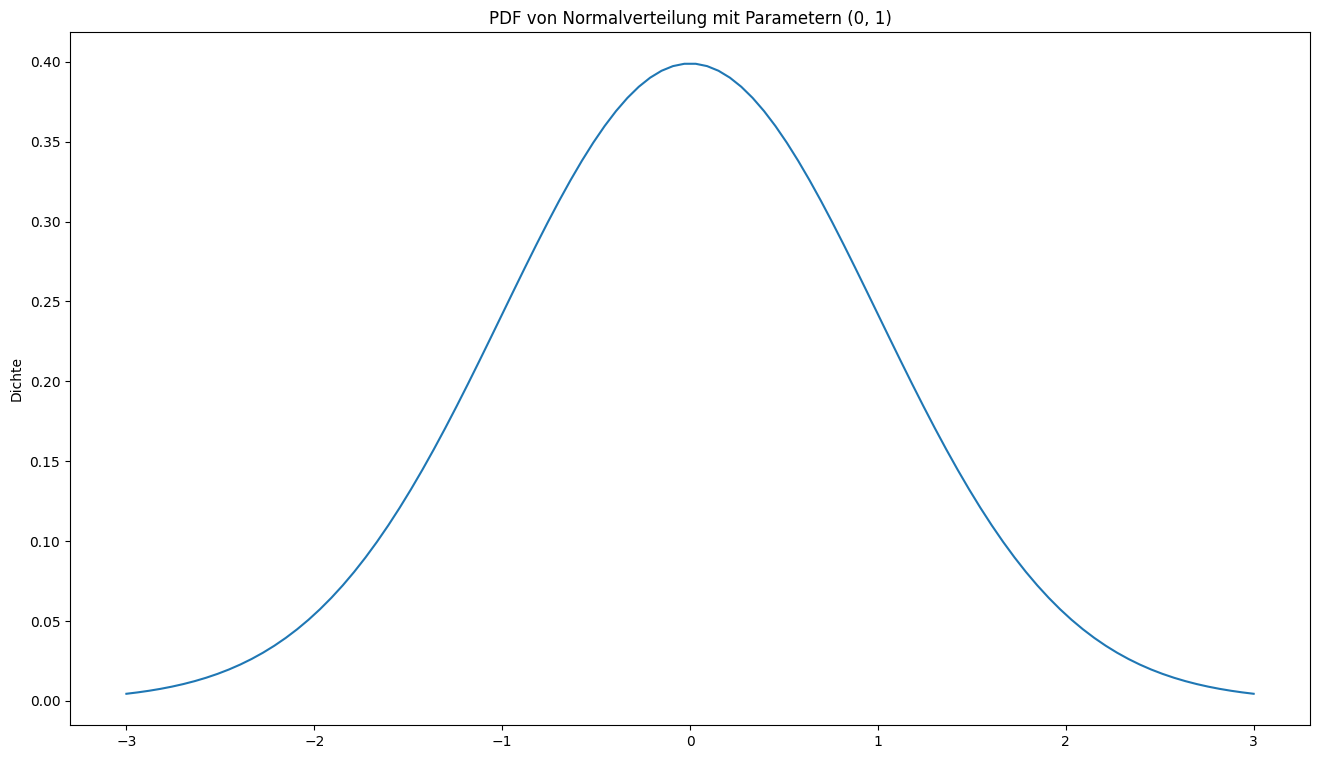

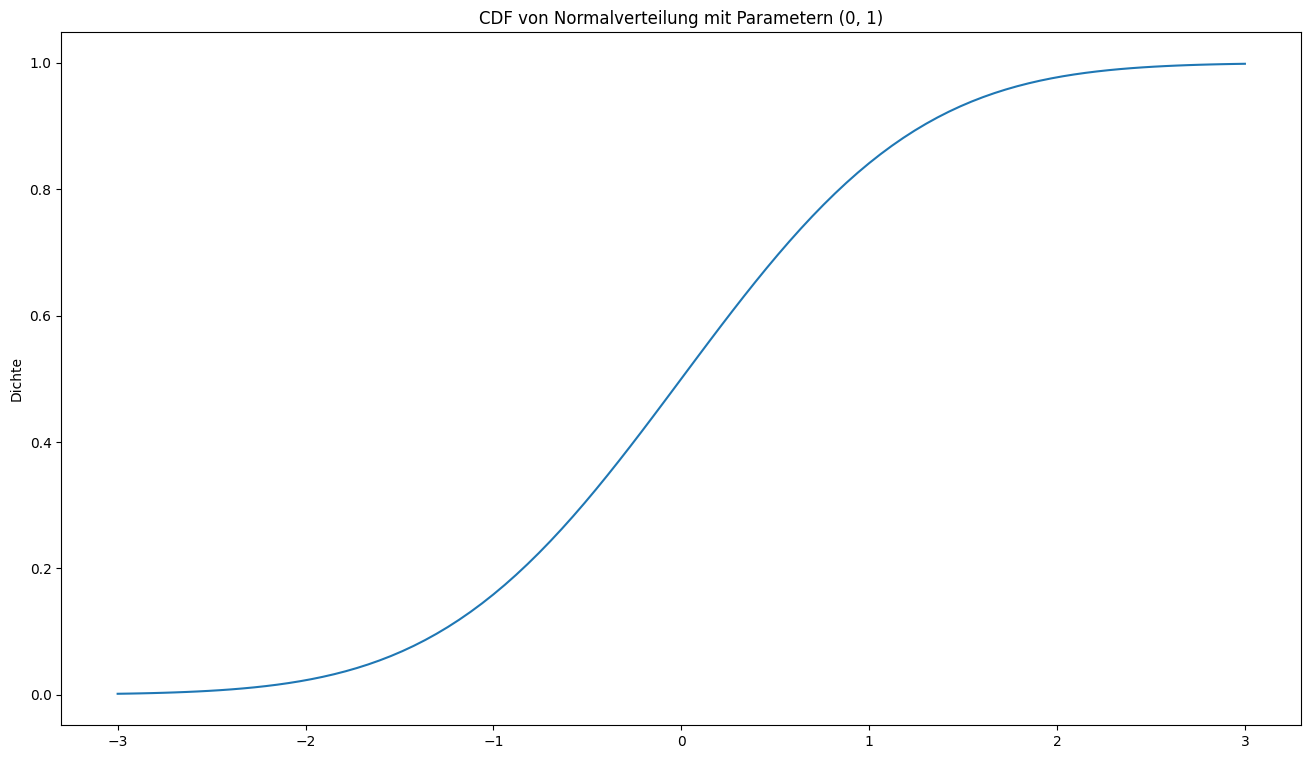

In [7]:
# Für Plots:
def plotX(x, X, name, params):
    # Zuerst die Dichtefunktion:
    plt.plot(x, X.pdf(x))
    plt.ylabel('Dichte')
    plt.title("PDF von "+name+" mit Parametern "+repr(params))
    plt.show()
    # Dann die kumulative Verteilungsfunktion:
    plt.plot(x, X.cdf(x))
    plt.ylabel('Dichte')
    plt.title("CDF von "+name+" mit Parametern "+repr(params))
    plt.show()

x = np.linspace(-3,3,100)
mu, sigma = 0, 1
X = st.norm(loc=mu, scale=sigma)
name = "Normalverteilung"
plotX(x, X, name, (mu, sigma))

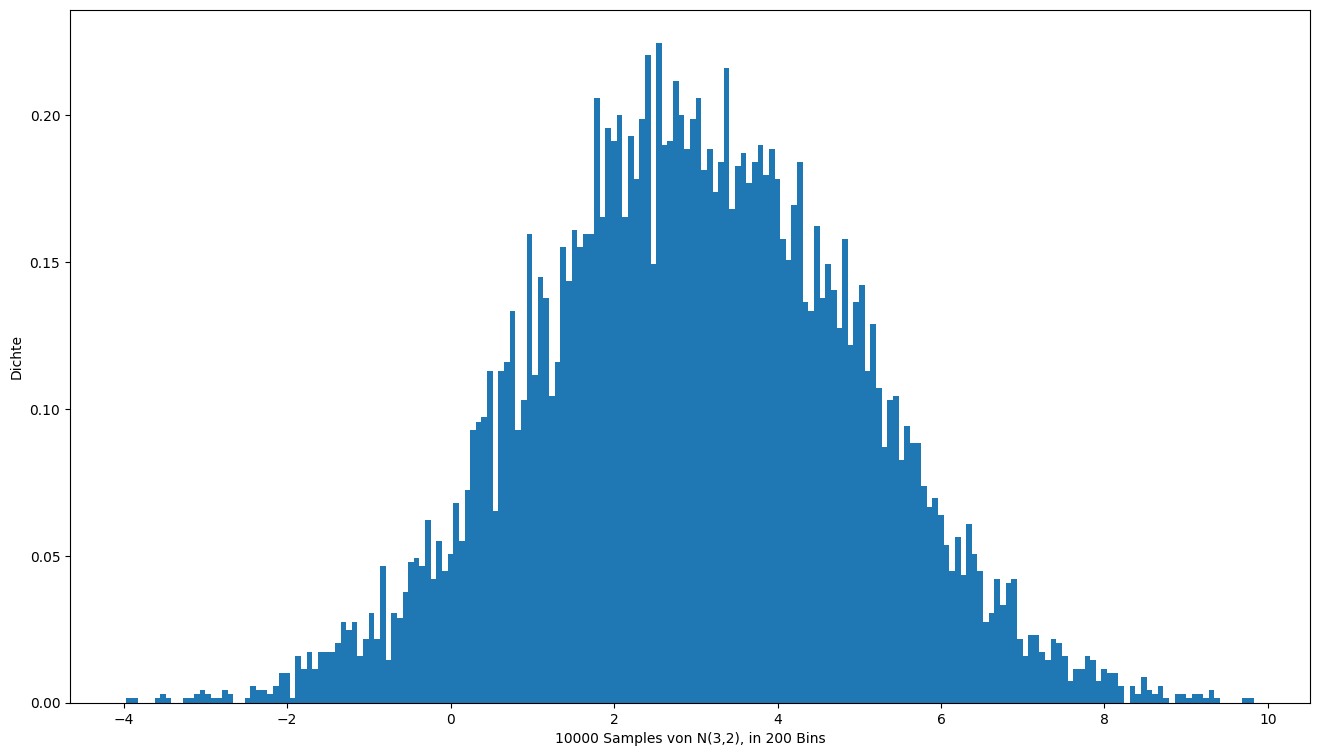

In [8]:
X = st.norm(loc=3, scale=2)
Xsamples = X.rvs(size=10000)
plt.hist(Xsamples, bins=200, density=True)
plt.xlabel("10000 Samples von N(3,2), in 200 Bins")
plt.ylabel("Dichte")
plt.show()

## Kontaminierte Normalverteilung

Die kontaminierte Normalverteilung ist ein einfacher Fall eines sogenannten *gemischten Modells*, genauer einer *Gaussschen Mischung*.

* Parameter $\varepsilon,\mu_1,\sigma_1,\mu_2,\sigma_2$, Notation $\varepsilon\mathcal{N}(\mu_1,\sigma_1^2) + (1-\varepsilon)\mathcal{N}(\mu_2,\sigma_2^2)$
* Dichte $\phi(x) = \frac{\varepsilon}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu_1)^2}{2\sigma_1^2}} + \frac{1 - \varepsilon}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu_2)^2}{2\sigma_2^2}}$
* Erwartungswert $\varepsilon\mu_1 + (1-\varepsilon)\mu_2$
* Varianz $\varepsilon\sigma_1^2 + (1 - \varepsilon)\sigma_2^2 + \varepsilon(1 - \varepsilon)(\mu_1-\mu_2)^2$
* Anwendungsbeispiele: Ein zweistufiger Prozess, je nach Ausgang eines Bernoulli-Experiments wird eine andere Normalverteilung gesampelt. Ein konkreter Versuchsaufbau wäre etwa, in einer Informatikvorlesung die Körpergröße der Teilnehmer\*innen zu messen. Das Geschlecht ist (näherungsweise!) Bernoulli-verteilt (voraussichtlich nicht gleichverteilt), innerhalb der Geschlechtergruppen ist die Körpergröße dann normalverteilt (aber mit verschiedenen Mittelwerten). An diesem Beispiel sieht man auch, dass jede Modellierung das Potential birgt, einen Teil der Realität unsichtbar zu machen, den man möglicherweise gar nicht unsichtbar machen möchte. Zum Glück kann man gemischte Modelle auch mit mehr als einem Parameter $\varepsilon$ aufstellen.

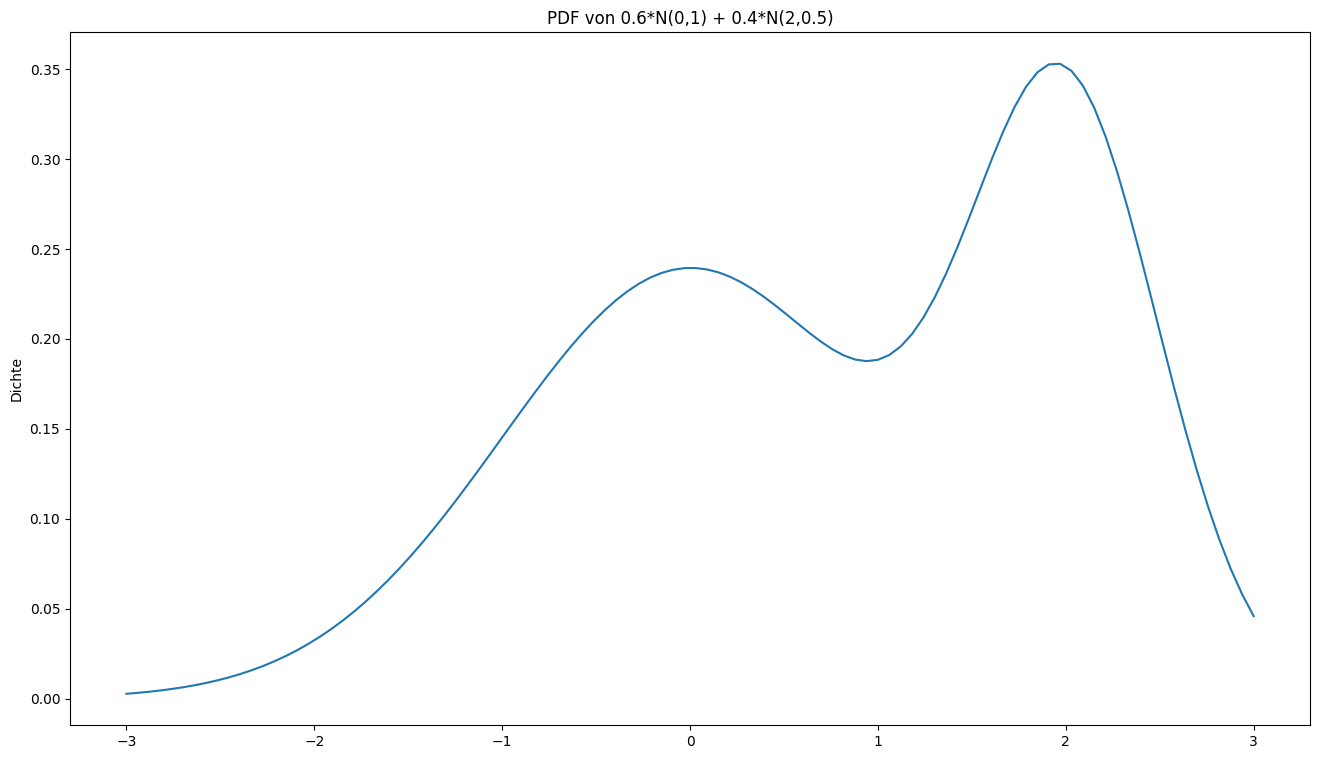

In [9]:
name = "0.6*N(0,1) + 0.4*N(2,0.5)"
def f(x, epsilon=0.6, mu1=0, sigma1=1, mu2=2, sigma2=0.5):
    norm1 = st.norm(loc=mu1, scale=sigma1)
    norm2 = st.norm(loc=mu2, scale=sigma2)
    return epsilon*norm1.pdf(x) + (1-epsilon)*norm2.pdf(x)

x = np.linspace(-3,3,100)
plt.plot(x, f(x))
plt.ylabel('Dichte')
plt.title("PDF von "+name)
plt.show()

## Dirac-Verteilung

* Parameter $\xi$, Notation $\delta(\xi)$
* Ohne Dichte, aber $P(X = \xi) = 1$
* Erwartungswert $\xi$
* Varianz $0$
* Entropie $0$
* Anwendungsbeispiele:
  * 'Dichtefunktionen' im stetigen Sinne für diskrete Verteilungen hinschreiben
  * Fotos vom Sternenhimmel (z.B. mit Hubble) - jeder Stern ist ein verschmierter Pixelhaufen (normalverteilt), aber die 'eigentliche' Verteilung der Sterne dahinter ist eine Summe von Dirac-Maßen, denn jeder Stern ist an genau einem Punkt (die tatsächliche Ausdehnung des Sterns ist aufgrund der Entfernung irrelevant). Mit dieser Modellierung arbeiten manche Superresolution-Techniken.
  
Die Dirac-Verteilung ist strenggenommen unplotbar (denn es gibt ja keine Dichte). Manche zeichnen zur Illustration einen Pfeil der Länge $1$ bei $\xi$ ein.
Die kumulative Verteilungsfunktion ist eine Heaviside-Step-Funktion:

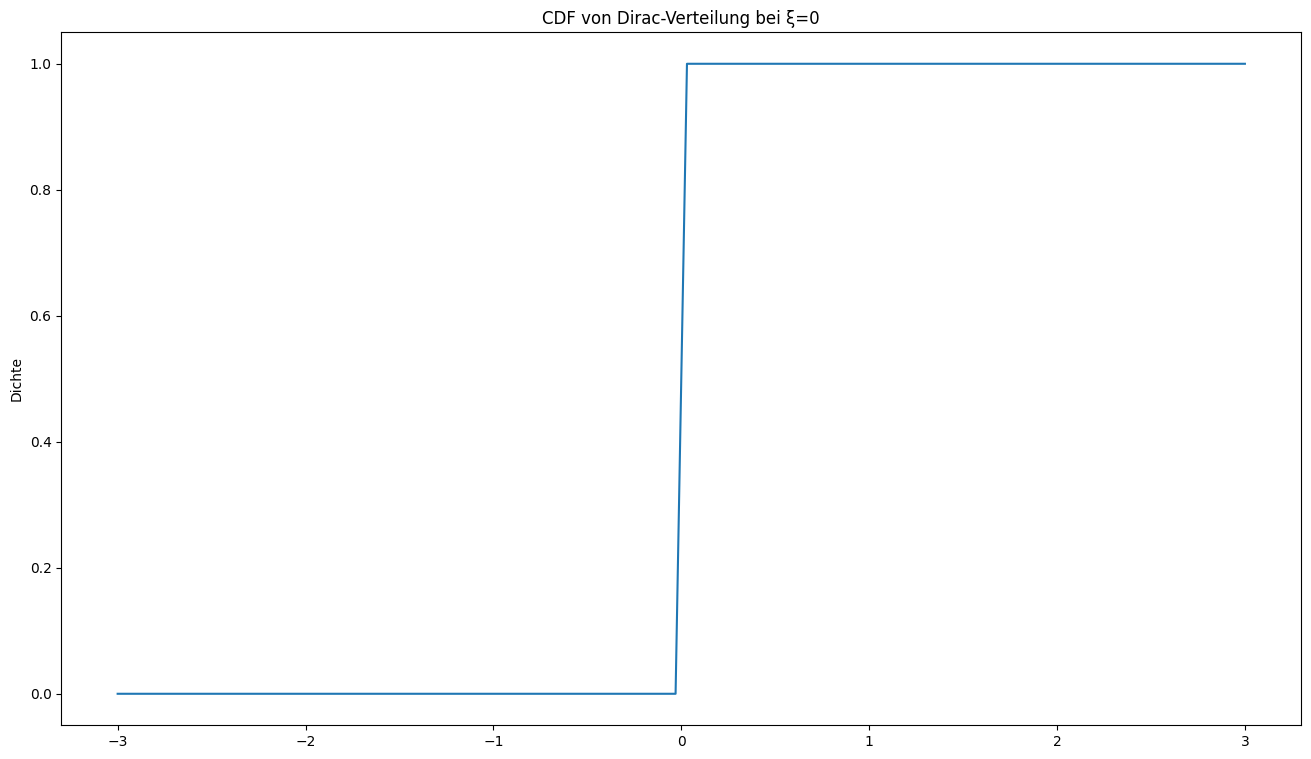

In [10]:
name = "Dirac-Verteilung bei ξ=0"
plt.plot(x, np.heaviside(x, 1))
plt.ylabel('Dichte')
plt.title("CDF von "+name)
plt.show()

## Stetige Gleichverteilung

* Parameter $a,b$, Notation $Uni(a,b)$
* Dichte $\frac{1}{b-a}$
* Erwartungswert $\frac{a+b}{2}$
* Varianz $\frac{(a-b)^2}{12}$
* Maximale Entropie unter allen Verteilungen mit Träger $[a,b]$
* Anwendungsbeispiele:
  * Wenn ein Bus an Ihrer Haltestelle extrem pünktlich jede Stunde kommt, Sie aber nicht wissen, wann er das letzte Mal gefahren ist, so ist ihre Wartezeit an der Haltestelle in Minuten gleichverteilt in $[0,60]$.
  * Die Temperatur ihrer CPU ab der dritten Nachkommastelle `(T * 100 - int(T * 100))` ist annähernd gleichverteilt.

0.5 0.75


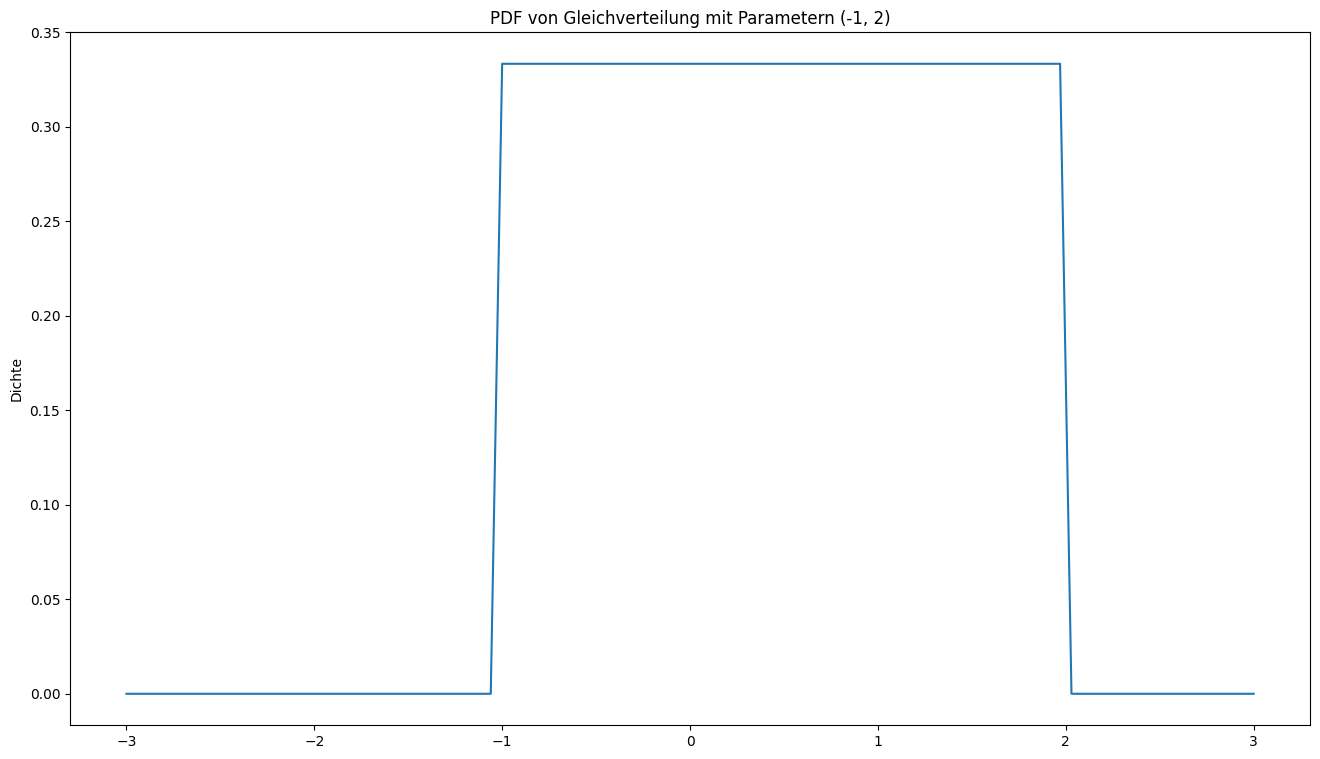

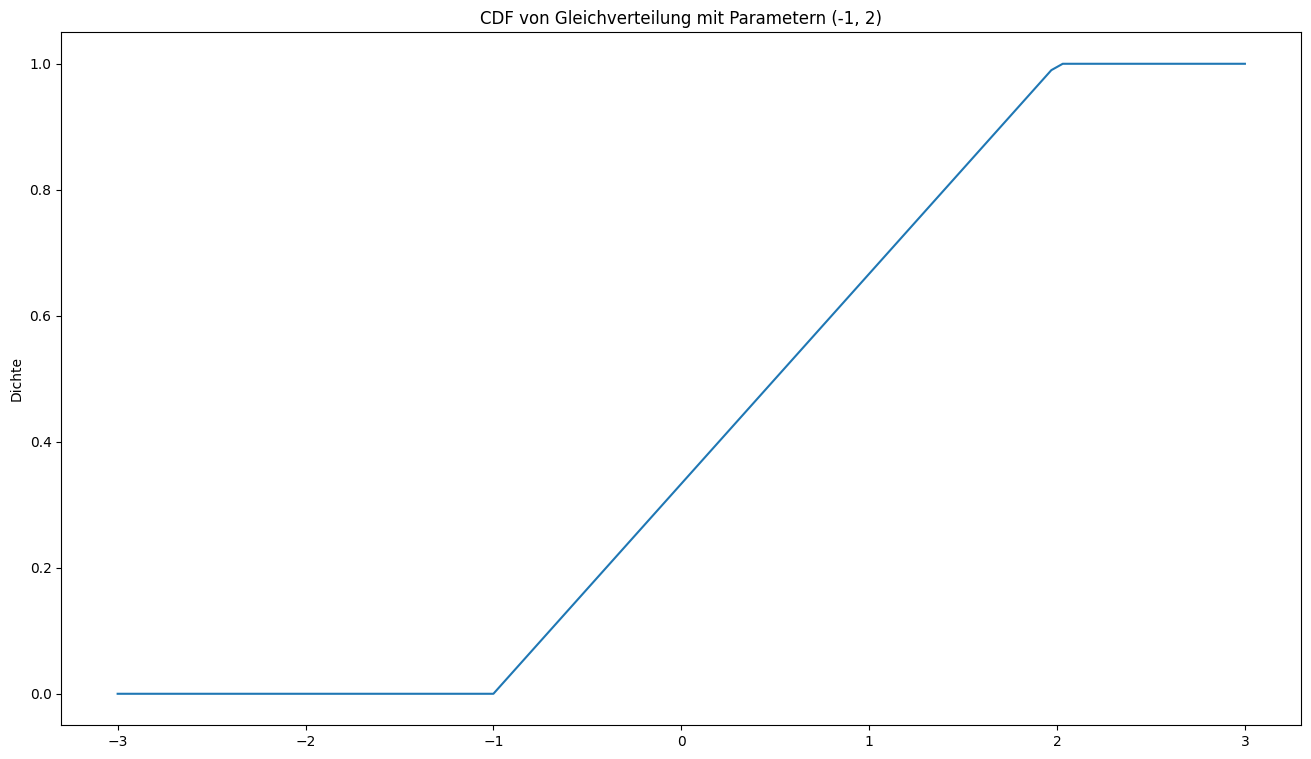

In [11]:
a, b = -1, 2
X = st.uniform(loc=a, scale=b-a)
print(X.mean(), X.var())
name = "Gleichverteilung"
plotX(x, X, name, (a, b))

## Exponentialverteilung

* Parameter $\lambda$, Notation $Exp(\lambda)$
* Dichte $\lambda e^{-\lambda x}$
* Erwartungswert $\dfrac{1}{\lambda}$
* Varianz $\dfrac{1}{\lambda^2}$
* Maximale Entropie unter allen Verteilungen mit Träger $[0,\infty)$ und Erwartungswert $\dfrac{1}{\lambda}$
* Anwendungsbeispiele:
  * Wie lange dauert es, bis auf dem Server das nächste Paket ankommt?

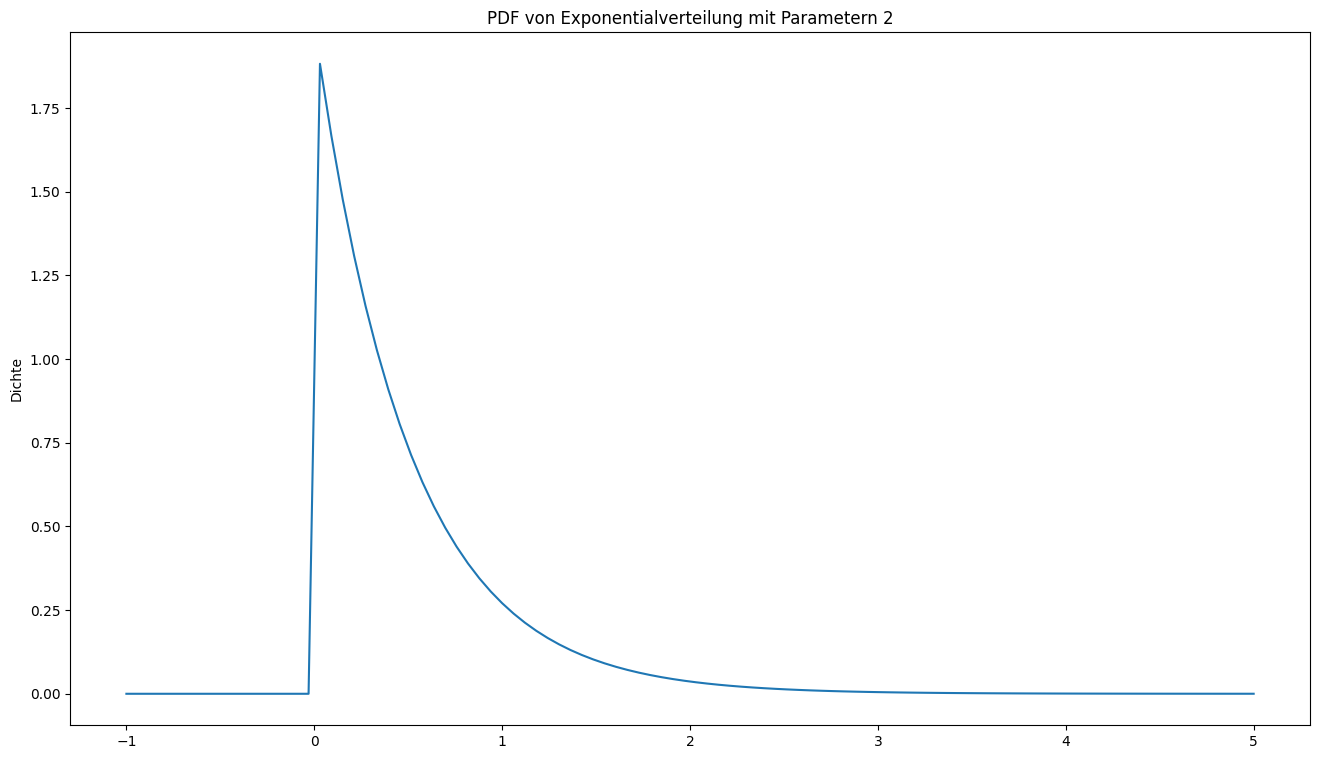

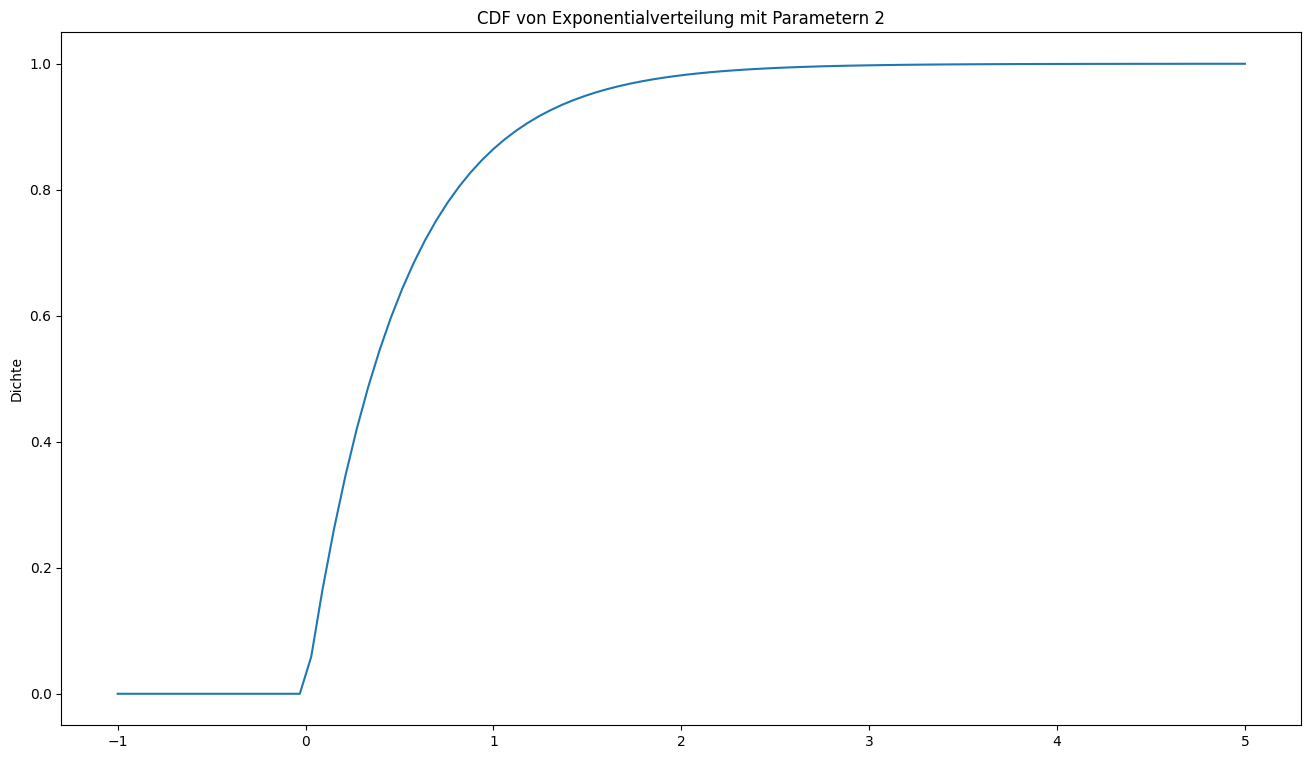

In [12]:
name = "Exponentialverteilung"
lamda = 2
X = st.expon(scale = 1/lamda)
x = np.linspace(-1,5,100)
plotX(x,X,name,(lamda))

## Lognormalverteilung

* Parameter $\mu, \sigma$, Notation $Lognormal(\mu,\sigma^2)$
* Dichte $\frac{1}{x\sigma\sqrt{2\pi}} e^{-\frac{(log(x)-\mu)^2}{2\sigma^2}}$
* Erwartungswert $e^{\mu + \frac{\sigma^2}{2}}$ aber $\mathbb{E}(log X) = \mu$ 
* Varianz $(e^{\sigma^2}-1)e^{2\mu + \sigma^2}$ aber $\mathbb{V}(log X) = \sigma^2$ 
* Maximale Entropie unter allen Verteilungen mit Träger $(0,\infty)$ und $\mathbb{E}(\log X) = \mu$ und $\mathbb{V}(\log X) = \sigma^2$
* Anwendungsbeispiele:
  * Die Länge eines Schachspiels ist log-normalverteilt
  * Viele (!) weitere Beispiele hat die [Wikipedia zur Lognormalverteilung](https://en.wikipedia.org/wiki/Log-normal_distribution#Occurrence_and_applications)
  

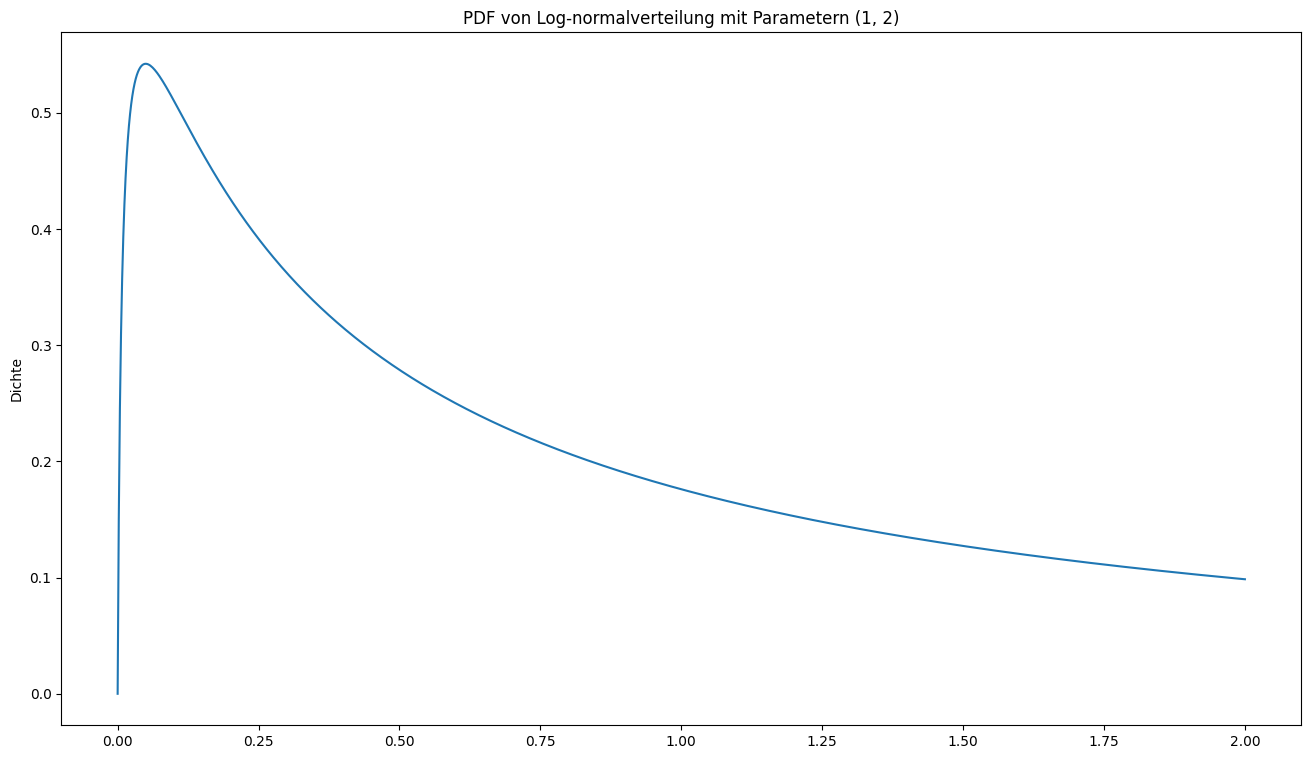

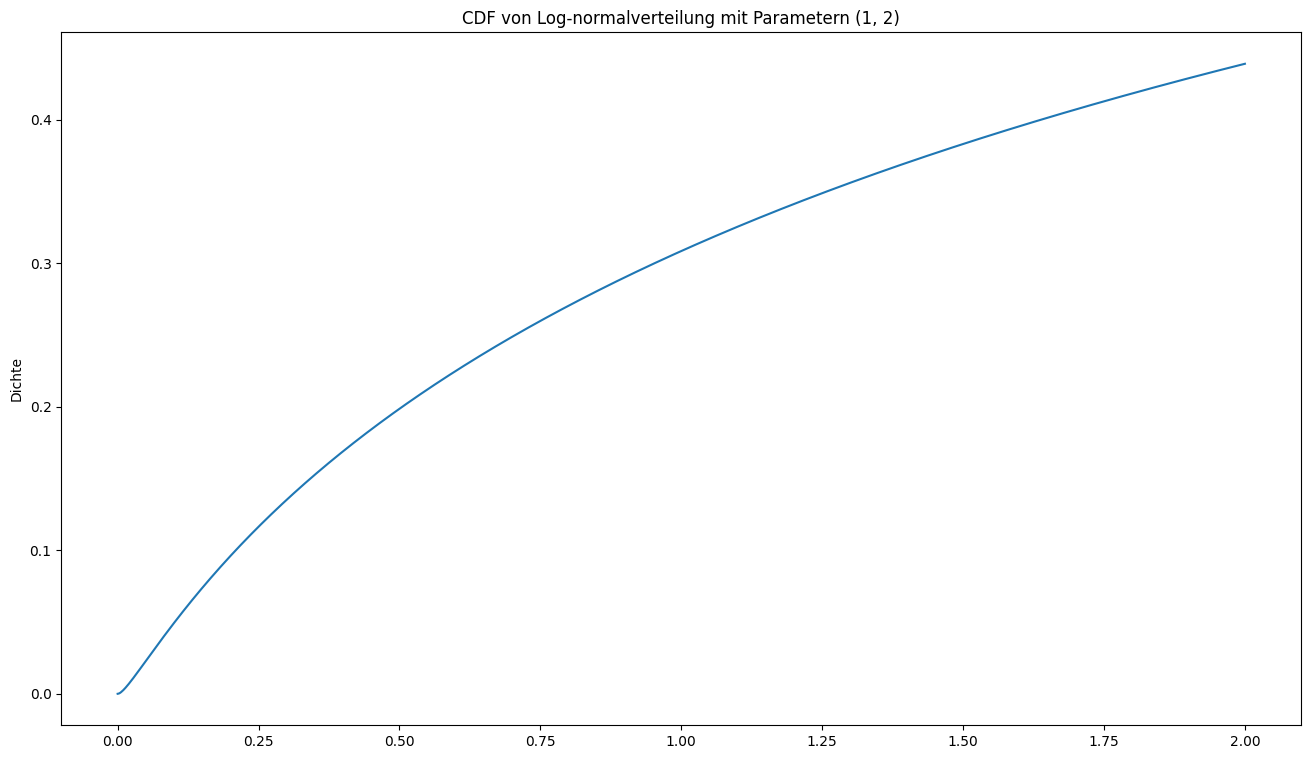

In [13]:
name = "Log-normalverteilung"
mu, sigma = 1, 2
X = st.lognorm(s=sigma, scale = np.exp(mu))
x = np.linspace(0,2,1000)
plotX(x,X,name,(mu, sigma))

## Weibull-Verteilung

* Parameter $\lambda>0, k>0$, Notation $Weibull(\lambda,k)$
* Dichte $f(x) = \dfrac{k}{\lambda}   {\left(\frac{x}{\lambda}\right)}^{k-1}    e^{-{\left(\frac{x}{\lambda}\right)}^k}$ für $x \geq 0$ \
  und $f(x)=0$ für $x < 0$
* Erwartungswert $\lambda \Gamma(1+\frac{1}{k})$ (wobei $\Gamma(n+1) = n!$)
* Maximale Entropie unter allen Verteilungen mit einer Bedingung an alle Momente: $\mathbb{E}(X^n) = \lambda^n$ und einer Bedingung an $\mathbb{E}(\log X)$.
* Anwendungsbeispiele:
  * Wie lange läuft eine Wärmepumpe, bis sie kaputt geht?
  * Wie hoch ist die Windgeschwindigkeit?
  * Was ist die höchste Niederschlagsmenge an einem einzelnen Tag im Jahr?
  

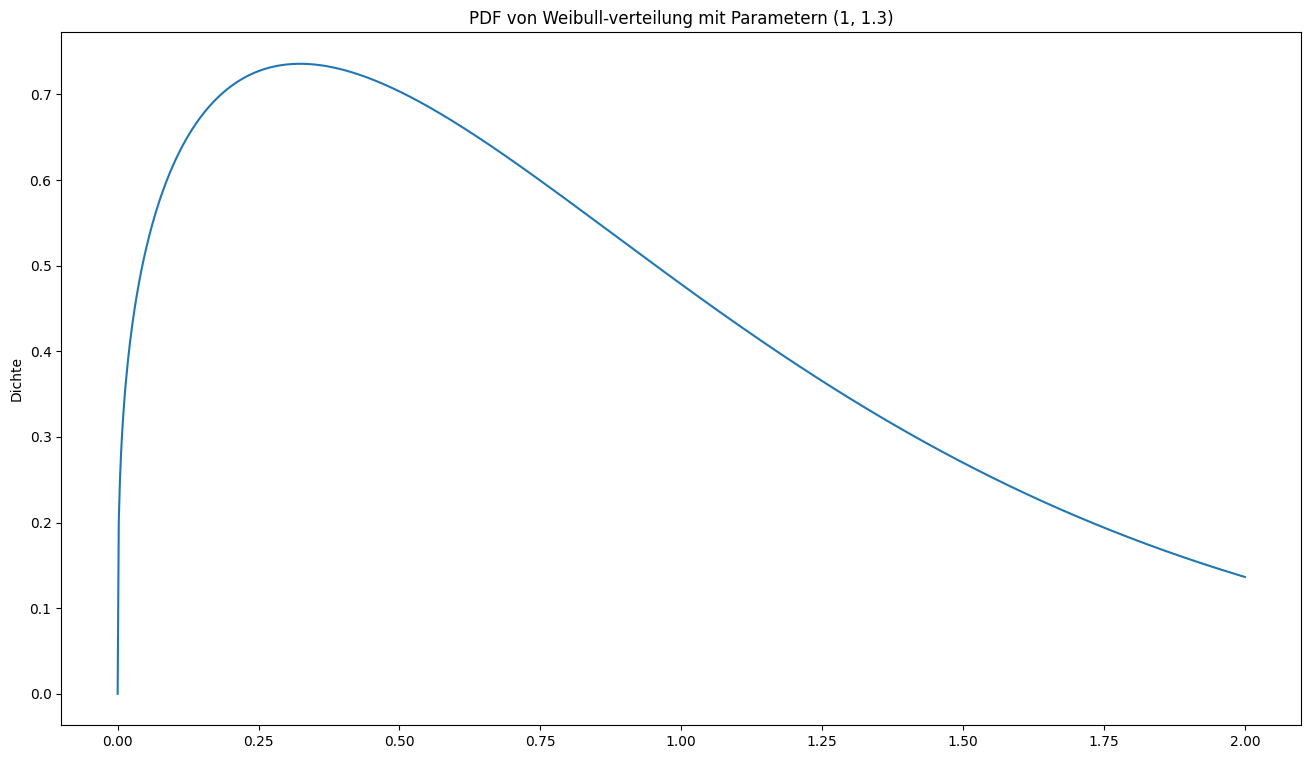

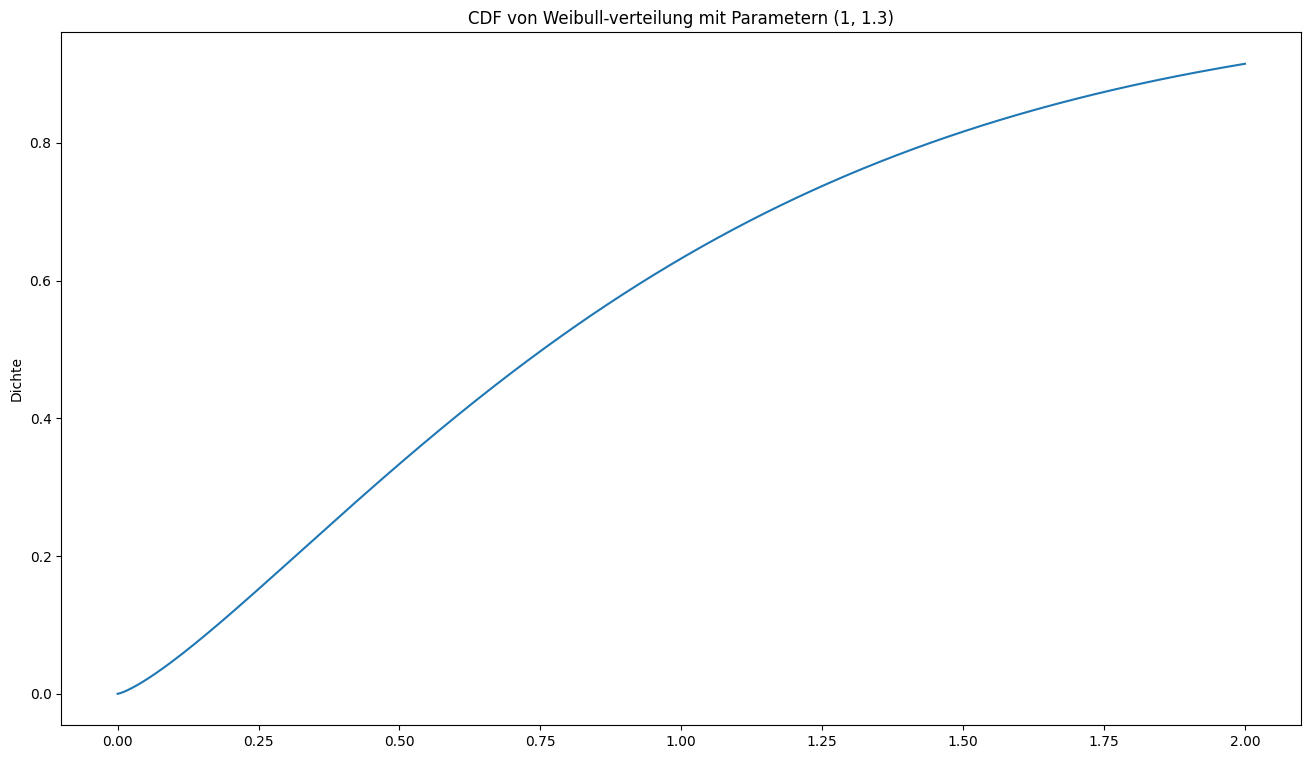

In [14]:
name = "Weibull-verteilung"
lamda, k = 1, 1.3
X = st.weibull_min(c=k, loc=0, scale = lamda)
x = np.linspace(0,2,1000)
plotX(x,X,name,(lamda, k))

## Daten zum plotten und fitten

Damit wir ein bisschen üben können, Daten zu plotten und Verteilungen auf Daten zu fitten (und das dann wiederum im Plot zu visualisieren), brauchen wir Spielzeugdaten.

Ein sehr einfacher und daher sehr instruktiver Datensatz ist Fisher-Anderson's 'iris flower dataset', den wir z.B. über Scikit-Learn beziehen können:

In [15]:
from sklearn import datasets
iris = datasets.load_iris()
print(iris["data"][:5])

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]


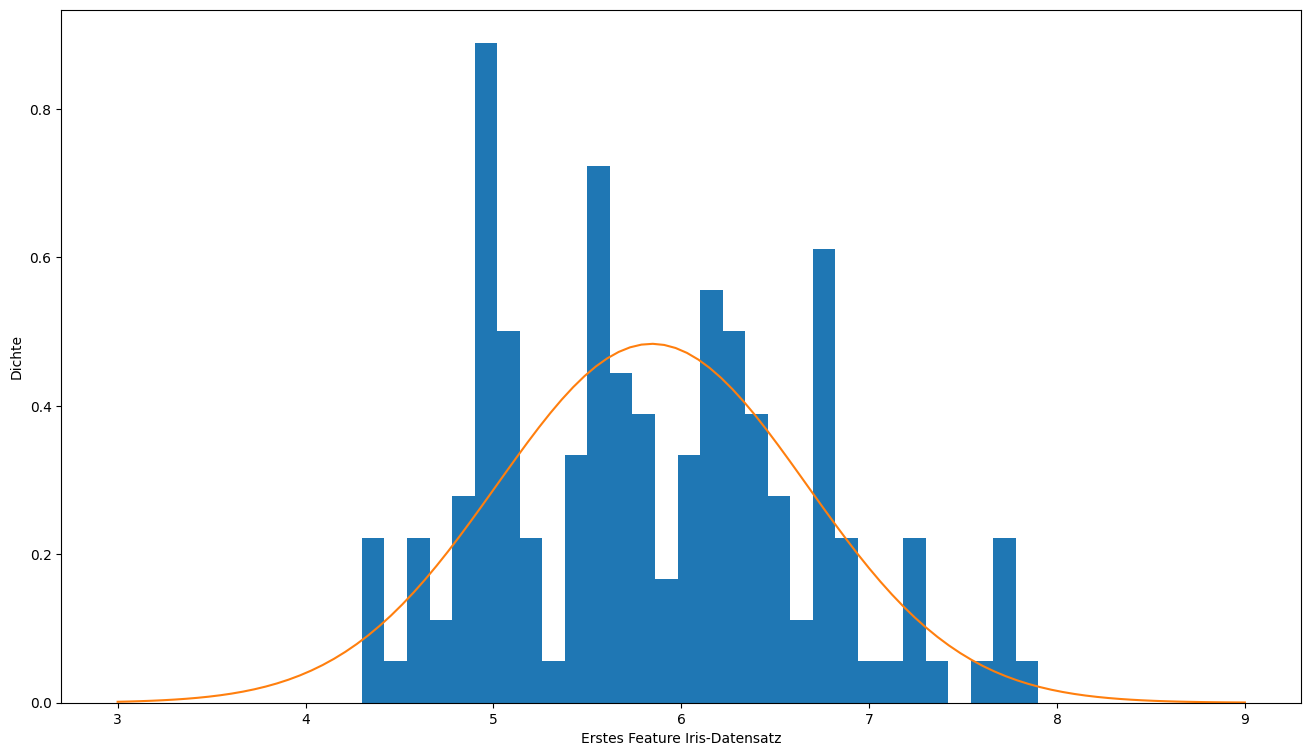

In [16]:
first_feature = iris["data"][:,0]
plt.hist(first_feature, bins=30, density=True)
# Jetzt die best-fitting-Normalverteilung rein:
mu, sigma = st.norm.fit(first_feature)
X = st.norm(loc=mu, scale=sigma)
x = np.linspace(3,9,100)
plt.plot(x, X.pdf(x))
plt.xlabel("Erstes Feature Iris-Datensatz")
plt.ylabel("Dichte")
plt.show()

Eine Quelle für relativ gut gepflegte Spielzeugdaten, die auch viel diskutiert werden, ist [Kaggle](https://www.kaggle.com/datasets).
Um diese Daten zu verarbeiten, muss man meist CSV-Dateien in Numpy-Arrays verwandeln. Besonders entspannt geht das mit Pandas (das auf Numpy aufbaut), womit wir uns noch beschäftigen werden. Für den Anfang reicht auch Numpy's eingebautes `np.genfromtxt`.

Der deutsche Wetterdienst DWD hat mit dem [Climate Data Center](https://cdc.dwd.de/portal/) eine große Sammlung gut dokumentierter, teilweise täglich aktualisierter Wetter- und Klimadaten. Darin sind Variablen mit räumlicher Verteilung und Zeitreihen verschiedenster physikalischer Größen und statistischer Verteilungen zu finden. Interessant (und beantwortbar) ist z.B. die Frage, ob Starkregenereignisse in Düsseldorf in den letzten Jahrzehnten zugenommen haben.

Schauen Sie sich diese (und andere!) Daten an, finden Sie heraus, wie die Variablen verteilt sein könnten, plotten und fitten Sie Verteilungen. Besonders durch den Vergleich des Histogramms mit der Dichtefunktion der gefitteten Verteilung sehen Sie, wie nah wir liegen.

Da sehr viele Daten nicht einer der hier aufgezählten Verteilungen genügen, benötigen wir noch komplexere Modelle. Diese sind allerdings zumeist mehrstufig aus den einfachen Modellen zusammengesetzt, wie bei der kontaminierten Normalverteilung. Eines der wichtigsten Modelle wird später die Mischung multivariater Normalverteilungen sein, anhand dessen wir einige Prinzipien des maschinellen Lernens betrachten können.

Wenn Sie sich weiter mit den Zusammenhängen zwischen den Verteilungen beschäftigen wollen, und dabei nicht übersehen haben, dass sich einige Verteilungen durchaus verschieden parametrisieren lassen (z.B. die Normalverteilung mit $\mu,\sigma$ aber auch mit $\mu,\sigma^2$), könnte ProbOnto das Richtige sein. Es handelt sich dabei um eine Ontologie und Wissensbasis, die ursprünglich für die Pharmakologie entwickelt wurde. Die Übersichtsgrafik ist bereits eine gute Gedächtnisstütze:

```{figure} images/ProbOnto2.5.jpg
---
width: 100%
name: probonto-diagram
---
[ProbOnto 2.5](https://commons.wikimedia.org/wiki/File:ProbOnto2.5.jpg) CC-BY-SA [Wikipedia user Fuzzyrandom](https://commons.wikimedia.org/w/index.php?title=User:Fuzzyrandom)